# Cost-aware gating for Welding Edge Detection
### Reproducible experiment notebook for the *Machine Learning with Applications* manuscript

This notebook produces **every number, table and figure used in the paper** from one top-to-bottom run.
All outputs are written to `RESULTS_DIR` (on Google Drive by default):

| Folder | Content |
|---|---|
| `tables/` | CSV files: dataset splits, leakage check, training history, validation sweep, per-frame test predictions, benchmark timings, ablation, stress test, seed variability |
| `figures/` | All figures (PNG, 300 dpi, and PDF) |
| `logs/` | `environment.json`, `config.json`, model summary, parameter counts |
| `overleaf/` | **Ready to upload to Overleaf:** `results_macros.tex` + `figures/` with the exact file names used by the manuscript (also zipped as `overleaf_update.zip`) |
| `results_summary.json` | Every reported number in one machine-readable file |

**How to run (Colab):** `Runtime -> Run all`. The first cell may install OpenCV 4.x and restart the runtime once; then run all again.

**Runtime on a CPU-only Colab runtime (the configuration reported in the paper):** about 45 min for the gate, about 3 h for the ablation (4 variants x 50 epochs), about 10 min for the benchmark. A GPU runtime speeds up training; the latency benchmark is always pinned to the CPU.

**Fixes relative to `publication_ready_notebook_v1.ipynb`:**
1. OpenCV 5 removed the Caffe importer (`readNetFromCaffe`), so HED failed to load. OpenCV 4.x is now pinned.
2. Seeds did not control Keras 3 random layers, so two runs gave different gates. Now `keras.utils.set_random_seed` is used and every random layer gets a seed.
3. The old benchmark computed the gate scores *before* starting the timer, so the reported pipeline latency excluded the gate. The gate and the conditional HED call are now timed together.
4. The demo pipeline fed BGR images (`cv2.imread`) to a gate trained on RGB images. Fixed.
5. Undefined precision (no positive predictions) is reported as *n/a*, not 0%.
6. Qualitative figures use a fixed set of frames instead of a random sample, and no longer print one-off latencies.

## 1. Environment

In [ ]:
# --- 1.1 Colab / Drive and OpenCV version check -------------------------------
import os, sys, subprocess, importlib

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
SMOKE_TEST = os.environ.get("MLWA_SMOKE_TEST", "0") == "1"   # quick dry run only; never use for the paper

if IN_COLAB and not SMOKE_TEST:
    from google.colab import drive
    drive.mount("/content/drive")

REQUIRED_OPENCV = "4.12.0.88"   # OpenCV 5.x removed the Caffe importer needed for HED

def _opencv_has_caffe():
    try:
        import cv2
        return hasattr(cv2, "dnn") and hasattr(cv2.dnn, "readNetFromCaffe") and hasattr(cv2, "dnn_registerLayer")
    except ImportError:
        return False

if not _opencv_has_caffe():
    print(f"OpenCV without Caffe support detected -> installing opencv-python-headless=={REQUIRED_OPENCV}")
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "opencv-python", "opencv-contrib-python",
                    "opencv-python-headless", "opencv-contrib-python-headless"], check=False)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"opencv-python-headless=={REQUIRED_OPENCV}"], check=True)
    print("\n>>> OpenCV installed. The runtime will now restart. Afterwards choose 'Run all' again. <<<")
    if IN_COLAB:
        os.kill(os.getpid(), 9)
    raise SystemExit("Restart the kernel and run the notebook again.")
print("OpenCV with Caffe importer available.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OpenCV with Caffe importer available.


In [ ]:
# --- 1.2 Imports, versions, hardware -----------------------------------------
import json, glob, time, random, platform, shutil, re, datetime
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from scipy.stats import beta
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve
from IPython.display import display

def _cpu_model():
    try:
        for line in open("/proc/cpuinfo"):
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or "unknown"

def _ram_gb():
    try:
        for line in open("/proc/meminfo"):
            if line.startswith("MemTotal"):
                return round(int(line.split()[1]) / 1024**2, 1)
    except OSError:
        return None

ENV = {
    "timestamp_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "opencv": cv2.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "cpu_model": _cpu_model(),
    "cpu_logical_cores": os.cpu_count(),
    "ram_gb": _ram_gb(),
    "gpus": [d.name for d in tf.config.list_physical_devices("GPU")],
    "opencv_threads": cv2.getNumThreads(),
    "in_colab": IN_COLAB,
    "smoke_test": SMOKE_TEST,
}
for k, v in ENV.items():
    print(f"{k:>18}: {v}")

     timestamp_utc: 2026-10-17 00:32:48
            python: 3.13.16
        tensorflow: 2.21.0
             keras: 3.13.2
            opencv: 4.12.0
             numpy: 2.1.3
            pandas: 2.2.3
         cpu_model: Intel(R) Xeon(R) CPU @ 2.20GHz
 cpu_logical_cores: 2
            ram_gb: 12.7
              gpus: []
    opencv_threads: 2
          in_colab: True
        smoke_test: False


## 2. Configuration
All hyper-parameters reported in the paper (Table 3) are defined here and saved to `logs/config.json`.

`IMG_SIZE` is **(height, width)** as Keras expects, i.e. frames are resized to 300 px high and 146 px wide. This is kept as in the original experiments so that the published model and results stay consistent.

In [ ]:
BASE_DIR = os.environ.get("MLWA_BASE_DIR", "/content/drive/MyDrive/M2Project")

CONFIG = {
    # data
    "TRAIN_DIR": os.path.join(BASE_DIR, "train_resized"),
    "VALID_DIR": os.path.join(BASE_DIR, "valid_resized"),
    "TEST_DIR":  os.path.join(BASE_DIR, "test_resized"),
    "IMG_SIZE": (300, 146),            # (height, width)
    "CHANNELS": 3,
    "BATCH_SIZE": 32,
    # Stage-1 gate
    "BACKBONE_WEIGHTS": "imagenet",
    "DROPOUT": 0.20,
    "L2": 0.01,
    "FOCAL_GAMMA": 2.0,
    "FOCAL_ALPHA": 0.25,
    "AUG_TRANSLATION": 0.10,
    "AUG_BRIGHTNESS": 0.20,
    "INIT_LR": 1e-4,                   # phase 1: head only
    "INIT_EPOCHS": 35,
    "FINE_LR": 1e-6,                   # phase 2: conv5_block3 unfrozen
    "MAX_EPOCHS": 95,                  # i.e. up to 60 fine-tuning epochs
    "UNFREEZE_PREFIX": "conv5_block3",
    "ES_PATIENCE": 8,
    "TAU": 0.35,                       # operating threshold of the gate
    "SEED": 1337,
    # Stage-2 HED (Caffe model, OpenCV DNN)
    "HED_PROTOTXT": os.environ.get("MLWA_HED_PROTOTXT", "/content/drive/MyDrive/Holistically-Nested_Edge_Detection/deploy.prototxt"),
    "HED_MODEL":    os.environ.get("MLWA_HED_MODEL", "/content/drive/MyDrive/Holistically-Nested_Edge_Detection/hed_pretrained_bsds.caffemodel"),
    "HED_MEAN": (104.00698793, 116.66876762, 122.67891434),
    # benchmark
    "BENCH_WARMUP": 3,
    "BENCH_REPEATS": 5,
    # ablation (protocol of the original experiments)
    "ABLATION_EPOCHS": 50,
    "ABLATION_LR": 1e-4,
    "ABLATION_DROPOUT": 0.25,
    # outputs
    "GATE_MODEL_SAVE_PATH": os.path.join(BASE_DIR, "models", "classifier_mlwa.keras"),
    "RESULTS_DIR": os.path.join(BASE_DIR, "results_mlwa"),
}

# ---- run switches ----
TRAIN_GATE = os.environ.get("MLWA_TRAIN_GATE", "1") == "1"   # set False to load CONFIG["GATE_MODEL_SAVE_PATH"] instead of training
RUN_ABLATION = True          # about 3 h on CPU; results are cached in tables/ablation.csv
FORCE_ABLATION = False       # True: retrain the ablation even if tables/ablation.csv exists
SEED_VARIABILITY = []        # e.g. [42, 7, 2024, 99] -> retrain the full gate per seed (about 45 min each on CPU)

if SMOKE_TEST:   # tiny settings to check that every cell runs; numbers are meaningless
    CONFIG.update({"BACKBONE_WEIGHTS": None, "INIT_EPOCHS": 1, "MAX_EPOCHS": 3, "ES_PATIENCE": 1,
                   "ABLATION_EPOCHS": 1, "BENCH_REPEATS": 1, "BENCH_WARMUP": 1})
    SEED_VARIABILITY = [42]

RESULTS_DIR = CONFIG["RESULTS_DIR"]
DIRS = {k: os.path.join(RESULTS_DIR, k) for k in ["tables", "figures", "logs", "models", "overleaf"]}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)
os.makedirs(os.path.dirname(CONFIG["GATE_MODEL_SAVE_PATH"]), exist_ok=True)

with open(os.path.join(DIRS["logs"], "config.json"), "w") as f:
    json.dump({**CONFIG, "TRAIN_GATE": TRAIN_GATE, "RUN_ABLATION": RUN_ABLATION,
               "SEED_VARIABILITY": SEED_VARIABILITY, "SMOKE_TEST": SMOKE_TEST}, f, indent=2)
with open(os.path.join(DIRS["logs"], "environment.json"), "w") as f:
    json.dump(ENV, f, indent=2)
print("Results will be written to:", RESULTS_DIR)

Results will be written to: /content/drive/MyDrive/M2Project/results_mlwa


In [ ]:
# --- 2.1 Reproducibility and helpers ----------------------------------------------
def set_all_seeds(seed):
    # Seeds Python, NumPy and the TensorFlow backend (covers Keras 3 random layers created afterwards)
    keras.utils.set_random_seed(seed)

tf.config.experimental.enable_op_determinism()
set_all_seeds(CONFIG["SEED"])

RESULTS = {}      # every number reported in the paper ends up here (and in results_summary.json)

def record(key, value, note=""):
    RESULTS[key] = {"value": value, "note": note}

def save_table(df, name, show=True):
    path = os.path.join(DIRS["tables"], f"{name}.csv")
    df.to_csv(path, index=False)
    if show:
        display(df)
    print(f"[saved] {path}")

def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(DIRS["figures"], f"{name}.{ext}"), dpi=300, bbox_inches="tight")
    print(f"[saved] figures/{name}.png/.pdf")

def clopper_pearson(k, n, alpha=0.05):
    # Exact two-sided binomial confidence interval
    if n == 0:
        return (np.nan, np.nan)
    lo = 0.0 if k == 0 else beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - alpha / 2, k + 1, n - k)
    return (float(lo), float(hi))

def binary_metrics(y_true, prob, thr):
    y_true = np.asarray(y_true).astype(int)
    y_pred = (np.asarray(prob) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    def ratio(a, b):
        return a / b if b else np.nan
    return {"threshold": thr, "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
            "passed": int(tp + fp), "n": int(len(y_true)),
            "recall": ratio(tp, tp + fn), "precision": ratio(tp, tp + fp),
            "specificity": ratio(tn, tn + fp), "fpr": ratio(fp, fp + tn),
            "accuracy": ratio(tp + tn, len(y_true))}

def pct(x, nd=1):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{100 * x:.{nd}f}"

## 3. Data
Frames are loaded exactly as in training (Keras loader, RGB, bilinear resize to 300x146). Evaluation uses unshuffled copies so that every prediction can be traced back to its file.

In [ ]:
def load_split(directory, shuffle, seed=CONFIG["SEED"]):
    return tf.keras.utils.image_dataset_from_directory(
        directory, label_mode="binary", image_size=CONFIG["IMG_SIZE"],
        batch_size=CONFIG["BATCH_SIZE"], shuffle=shuffle, seed=seed if shuffle else None)

def to_arrays(directory):
    ds = load_split(directory, shuffle=False)
    X = np.concatenate([x.numpy() for x, _ in ds]).astype(np.float32)
    y = np.concatenate([t.numpy() for _, t in ds]).astype(int).ravel()
    return X, y, list(ds.file_paths), list(ds.class_names)

Xtr, ytr, ftr, class_names = to_arrays(CONFIG["TRAIN_DIR"])
Xva, yva, fva, _ = to_arrays(CONFIG["VALID_DIR"])
Xte, yte, fte, _ = to_arrays(CONFIG["TEST_DIR"])
print("Class folders (label 0, label 1):", class_names, "-> label 1 is treated as 'joint' (positive)")
record("class_names", class_names)

split_rows = []
for name, y in [("Training", ytr), ("Validation", yva), ("Test", yte)]:
    split_rows.append({"split": name, "frames": len(y), "negative": int((y == 0).sum()),
                       "positive": int((y == 1).sum()), "positive_rate_%": round(100 * y.mean(), 1)})
    record(f"n_{name.lower()}", len(y)); record(f"n_{name.lower()}_pos", int(y.sum())); record(f"n_{name.lower()}_neg", int((y == 0).sum()))
save_table(pd.DataFrame(split_rows), "dataset_splits")

files_df = pd.DataFrame(
    [{"split": s, "file": os.path.basename(p), "label": int(l)} for s, P, Y in
     [("train", ftr, ytr), ("valid", fva, yva), ("test", fte, yte)] for p, l in zip(P, Y)])
save_table(files_df, "dataset_files", show=False)

Found 213 files belonging to 2 classes.
Found 85 files belonging to 2 classes.
Found 11 files belonging to 2 classes.
Class folders (label 0, label 1): ['no', 'yes'] -> label 1 is treated as 'joint' (positive)


,split,frames,negative,positive,positive_rate_%
0,Training,213,193,20,9.4
1,Validation,85,77,8,9.4
2,Test,11,10,1,9.1


[saved] /content/drive/MyDrive/M2Project/results_mlwa/tables/dataset_splits.csv
[saved] /content/drive/MyDrive/M2Project/results_mlwa/tables/dataset_files.csv


In [ ]:
# --- 3.1 Leakage check: are recordings / neighbouring frames shared across splits? ---
# File names look like img_<recording>_<id>_<frame>.jpg ; adjust the regex if your naming differs.
NAME_RE = re.compile(r"img_(\d+)_(\d+)_(\d+)")

def parse(fname):
    m = NAME_RE.search(fname)
    return (f"{m.group(1)}_{m.group(2)}", int(m.group(3))) if m else (None, None)

files_df[["recording", "frame_no"]] = files_df["file"].apply(lambda f: pd.Series(parse(f)))
rec_table = files_df.groupby(["recording", "split"]).size().unstack(fill_value=0)
print("Frames per recording and split:")
display(rec_table)
rec_table.reset_index().to_csv(os.path.join(DIRS["tables"], "recordings_per_split.csv"), index=False)

leak_rows = []
trainval = files_df[files_df.split != "test"]
for _, r in files_df[files_df.split == "test"].iterrows():
    same = trainval[trainval.recording == r.recording]
    gap = int((same.frame_no - r.frame_no).abs().min()) if len(same) and pd.notna(r.frame_no) else None
    leak_rows.append({"test_file": r.file, "label": r.label, "recording": r.recording,
                      "recording_in_train_or_val": len(same) > 0, "nearest_trainval_frame_gap": gap})
leak_df = pd.DataFrame(leak_rows)
save_table(leak_df, "leakage_check")
shared = int(leak_df.recording_in_train_or_val.sum())
record("test_frames_with_recording_in_trainval", shared, "test frames whose recording also appears in train/val")
record("test_min_frame_gap", None if leak_df.nearest_trainval_frame_gap.isna().all() else int(leak_df.nearest_trainval_frame_gap.min()))
print(f"{shared}/{len(leak_df)} test frames come from a recording that is also in train/val.")

Frames per recording and split:


split,test,train,valid
recording,,,
01_3436814600,0,1,0
01_3436815300,0,3,0
01_3437011300,0,1,0
01_425005700,10,123,0
01_425243200,0,1,0
01_425243300,0,5,0
01_425508300,0,1,0
01_425613800,0,1,0
01_425614600,0,1,0


,test_file,label,recording,recording_in_train_or_val,nearest_trainval_frame_gap
0,img_01_425005700_00447.jpg,0,01_425005700,True,1.0
1,img_01_425005700_00451.jpg,0,01_425005700,True,5.0
2,img_01_425005700_00453.jpg,0,01_425005700,True,7.0
3,img_01_425005700_00463.jpg,0,01_425005700,True,7.0
4,img_01_425005700_00464.jpg,0,01_425005700,True,6.0
5,img_01_425005700_00465.jpg,0,01_425005700,True,5.0
6,img_01_425005700_00466.jpg,0,01_425005700,True,4.0
7,img_01_425005700_00467.jpg,0,01_425005700,True,3.0
8,img_01_425005700_00468.jpg,0,01_425005700,True,2.0
9,img_01_425005700_00469.jpg,0,01_425005700,True,1.0


[saved] /content/drive/MyDrive/M2Project/results_mlwa/tables/leakage_check.csv
10/11 test frames come from a recording that is also in train/val.


In [ ]:
# --- 3.2 Class weights (Eqs. 1-2) and training pipeline -------------------------------
n_neg, n_pos = int((ytr == 0).sum()), int((ytr == 1).sum())
n_tot = n_neg + n_pos
class_weights = {0: (1 / n_neg) * (n_tot / 2.0), 1: (1 / n_pos) * (n_tot / 2.0)}
print(f"W0 = {class_weights[0]:.4f} | W1 = {class_weights[1]:.4f} | W1/W0 = {class_weights[1]/class_weights[0]:.2f}")
record("W0", round(class_weights[0], 4)); record("W1", round(class_weights[1], 4))
record("net_pos_weight", round(class_weights[1] * CONFIG["FOCAL_ALPHA"] / (class_weights[0] * (1 - CONFIG["FOCAL_ALPHA"])), 2),
       "W1*alpha / (W0*(1-alpha))")

def train_val_datasets(seed):
    tr = load_split(CONFIG["TRAIN_DIR"], shuffle=True, seed=seed).prefetch(tf.data.AUTOTUNE)
    va = load_split(CONFIG["VALID_DIR"], shuffle=False).prefetch(tf.data.AUTOTUNE)
    return tr, va

W0 = 0.5518 | W1 = 5.3250 | W1/W0 = 9.65


## 4. Stage 1: training the gate
Two-phase micro-fine-tuning: (1) frozen ResNet50, head only; (2) only `conv5_block3` unfrozen, very small learning rate, early stopping on validation PR-AUC with the best weights restored.

In [ ]:
def build_gate(seed):
    input_shape = CONFIG["IMG_SIZE"] + (CONFIG["CHANNELS"],)
    backbone = tf.keras.applications.ResNet50(input_shape=input_shape, include_top=False,
                                              weights=CONFIG["BACKBONE_WEIGHTS"])
    backbone.trainable = False
    augmentation = tf.keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical", seed=seed),
        layers.RandomTranslation(CONFIG["AUG_TRANSLATION"], CONFIG["AUG_TRANSLATION"], seed=seed + 1),
        layers.RandomBrightness(CONFIG["AUG_BRIGHTNESS"], seed=seed + 2),
    ], name="structural_augmentation")       # active only during training
    inputs = layers.Input(shape=input_shape)
    x = augmentation(inputs)
    x = tf.keras.applications.resnet50.preprocess_input(x)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(CONFIG["DROPOUT"], seed=seed + 3)(x)
    outputs = layers.Dense(1, activation="sigmoid", kernel_regularizer=tf.keras.regularizers.l2(CONFIG["L2"]),
                           name="decision_node")(x)
    return models.Model(inputs, outputs, name="Trustworthy_Gate"), backbone

def compile_gate(model, lr):
    model.compile(optimizer=optimizers.Adam(learning_rate=lr),
                  loss=tf.keras.losses.BinaryFocalCrossentropy(gamma=CONFIG["FOCAL_GAMMA"], alpha=CONFIG["FOCAL_ALPHA"]),
                  metrics=["accuracy", tf.keras.metrics.Precision(name="precision"),
                           tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.AUC(curve="PR", name="pr_auc")])

def count_params(weights):
    return int(sum(np.prod(w.shape) for w in weights))

def train_gate(seed, tag):
    set_all_seeds(seed)
    tr_ds, va_ds = train_val_datasets(seed)
    model, backbone = build_gate(seed)
    compile_gate(model, CONFIG["INIT_LR"])
    params = {"total": model.count_params(), "trainable_phase1": count_params(model.trainable_weights)}
    t0 = time.time()
    h1 = model.fit(tr_ds, epochs=CONFIG["INIT_EPOCHS"], validation_data=va_ds,
                   class_weight=class_weights, verbose=2)
    # phase 2: unfreeze only the last residual block
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = layer.name.startswith(CONFIG["UNFREEZE_PREFIX"])
    compile_gate(model, CONFIG["FINE_LR"])
    params["trainable_phase2"] = count_params(model.trainable_weights)
    es = callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=CONFIG["ES_PATIENCE"],
                                 restore_best_weights=True, verbose=1)
    h2 = model.fit(tr_ds, epochs=CONFIG["MAX_EPOCHS"], initial_epoch=len(h1.epoch),
                   validation_data=va_ds, class_weight=class_weights, callbacks=[es], verbose=2)
    train_minutes = (time.time() - t0) / 60
    hist = pd.concat([pd.DataFrame(h1.history).assign(epoch=np.arange(1, len(h1.epoch) + 1), phase=1),
                      pd.DataFrame(h2.history).assign(epoch=np.array(h2.epoch) + 1, phase=2)], ignore_index=True)
    p2 = hist[hist.phase == 2]
    best_epoch = int(p2.loc[p2.val_pr_auc.idxmax(), "epoch"])   # first maximum = epoch restored by Keras
    info = {"seed": seed, "best_epoch": best_epoch, "stopped_epoch": int(hist.epoch.max()),
            "train_minutes": round(train_minutes, 1), **params}
    hist.to_csv(os.path.join(DIRS["tables"], f"training_history_{tag}.csv"), index=False)
    return model, hist, info

In [ ]:
HIST_PATH = os.path.join(DIRS["tables"], "training_history_main.csv")
INFO_PATH = os.path.join(DIRS["logs"], "training_info_main.json")

if TRAIN_GATE:
    classifier, history, train_info = train_gate(CONFIG["SEED"], "main")
    classifier.save(CONFIG["GATE_MODEL_SAVE_PATH"])
    shutil.copy(CONFIG["GATE_MODEL_SAVE_PATH"], os.path.join(DIRS["models"], "gate_main.keras"))
    with open(INFO_PATH, "w") as f:
        json.dump(train_info, f, indent=2)
else:
    classifier = tf.keras.models.load_model(CONFIG["GATE_MODEL_SAVE_PATH"])
    history = pd.read_csv(HIST_PATH) if os.path.exists(HIST_PATH) else None
    train_info = json.load(open(INFO_PATH)) if os.path.exists(INFO_PATH) else {
        "total": classifier.count_params(), "trainable_phase2": count_params(classifier.trainable_weights)}
    print("Loaded gate from", CONFIG["GATE_MODEL_SAVE_PATH"], "| training history available:", history is not None)

print(json.dumps(train_info, indent=2))
for k in ["best_epoch", "stopped_epoch", "total", "trainable_phase1", "trainable_phase2", "train_minutes"]:
    record(f"train_{k}", train_info.get(k))
with open(os.path.join(DIRS["logs"], "model_summary.txt"), "w") as f:
    classifier.summary(print_fn=lambda s, **kw: f.write(s + "\n"))

Found 213 files belonging to 2 classes.
Found 85 files belonging to 2 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/35
7/7 - 59s - 8s/step - accuracy: 0.4601 - loss: 0.3517 - pr_auc: 0.0676 - precision: 0.0561 - recall: 0.3000 - val_accuracy: 0.8588 - val_loss: 0.1213 - val_pr_auc: 0.4102 - val_precision: 0.3571 - val_recall: 0.6250
Epoch 2/35
7/7 - 81s - 12s/step - accuracy: 0.4319 - loss: 0.3433 - pr_auc: 0.0656 - precision: 0.0609 - recall: 0.3500 - val_accuracy: 0.8588 - val_loss: 0.1179 - val_pr_auc: 0.4467 - val_precision: 0.3571 - val_recall: 0.6250
Epoch 3/35
7/7 - 86s - 12s/step - accuracy: 0.5023 - loss: 0.2822 - pr_auc: 0.0924 - precision: 0.0865 - recall: 0.4500 - val_accuracy: 0.8588 - val_loss: 0.1183 - val_pr_auc: 0.5743 - val_precision: 0.3750 - val_recall: 0.7500
Epoch 4/35
7/7 - 54s - 8s/step - accuracy: 0.5117 - loss: 0.3008 - pr_auc: 0.0942 - precision: 0.0800 - recall: 0.4000 - val_accuracy: 0.8471 - val_loss: 0.1204 - val_pr_auc: 0.6305 - val

[saved] figures/fig_training_curves.png/.pdf


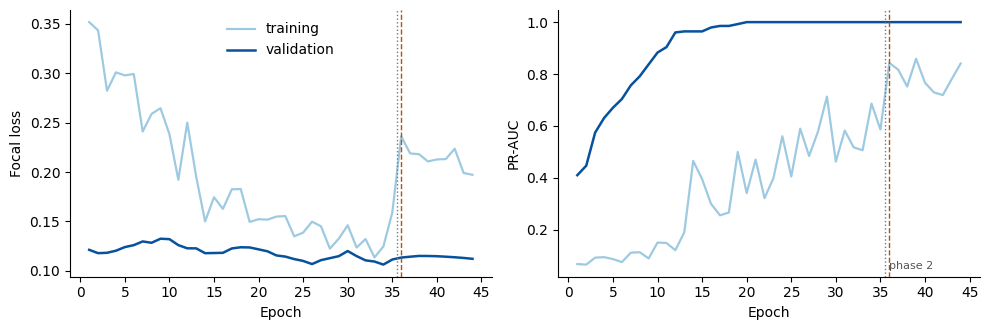

In [ ]:
# --- 4.1 Training curves ---------------------------------------------------------------
if history is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for ax, (tr, va, lab) in zip(axes, [("loss", "val_loss", "Focal loss"), ("pr_auc", "val_pr_auc", "PR-AUC")]):
        ax.plot(history.epoch, history[tr], color="#9ecae1", lw=1.6, label="training")
        ax.plot(history.epoch, history[va], color="#08519c", lw=1.8, label="validation")
        ax.axvline(CONFIG["INIT_EPOCHS"] + 0.5, color="#777777", ls=":", lw=1)
        if train_info.get("best_epoch"):
            ax.axvline(train_info["best_epoch"], color="#b5520c", ls="--", lw=1)
        ax.set_xlabel("Epoch"); ax.set_ylabel(lab)
        ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False)
    axes[1].text(CONFIG["INIT_EPOCHS"] + 1, 0.05, "phase 2", fontsize=8, color="#555555")
    fig.tight_layout(); save_fig(fig, "fig_training_curves"); plt.show()

## 5. Validation analysis and threshold
The operating threshold is fixed at tau = 0.35 (set below 0.5 because focal loss compresses the sigmoid outputs). This cell reports how the gate behaves on the validation set at tau and at 0.5, and a full threshold sweep for reference.

,threshold,TP,FP,FN,TN,passed,n,recall,precision,specificity,fpr,accuracy
0,0.35,8,62,0,15,70,85,1.0,0.114286,0.194805,0.805195,0.270588
1,0.50,8,10,0,67,18,85,1.0,0.444444,0.870130,0.129870,0.882353


Validation PR-AUC (sklearn, step-wise) = 1.0000
[saved] /content/drive/MyDrive/M2Project/results_mlwa/tables/validation_threshold_sweep.csv
[saved] figures/fig_validation_pr_curve.png/.pdf


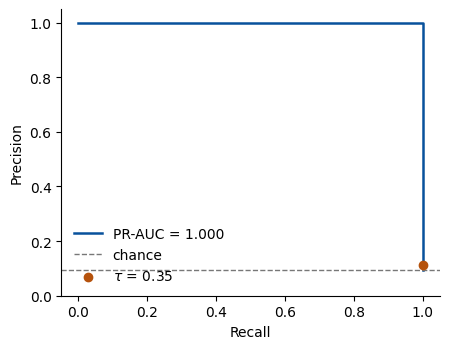

In [ ]:
@tf.function(reduce_retracing=True)
def _gate_batch(x):
    return classifier(x, training=False)

def gate_probs(X, bs=16):
    return np.concatenate([_gate_batch(tf.constant(X[i:i + bs])).numpy().ravel() for i in range(0, len(X), bs)])

pva = gate_probs(Xva)
TAU = CONFIG["TAU"]
val_tau, val_half = binary_metrics(yva, pva, TAU), binary_metrics(yva, pva, 0.5)
prec_c, rec_c, _ = precision_recall_curve(yva, pva)
val_prauc = auc(rec_c, prec_c)
display(pd.DataFrame([val_tau, val_half]))
print(f"Validation PR-AUC (sklearn, step-wise) = {val_prauc:.4f}")
for tag, m in [("tau", val_tau), ("half", val_half)]:
    for k in ["TP", "FP", "FN", "TN", "passed", "recall", "precision", "fpr"]:
        record(f"val_{tag}_{k}", m[k])
record("val_pr_auc", round(float(val_prauc), 4))

sweep = pd.DataFrame([binary_metrics(yva, pva, t) for t in np.round(np.arange(0.05, 0.96, 0.05), 2)])
save_table(sweep, "validation_threshold_sweep", show=False)
pd.DataFrame({"file": [os.path.basename(f) for f in fva], "label": yva, "prob": pva}).to_csv(
    os.path.join(DIRS["tables"], "validation_predictions.csv"), index=False)

fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.plot(rec_c, prec_c, color="#08519c", lw=1.8, label=f"PR-AUC = {val_prauc:.3f}")
ax.axhline(yva.mean(), color="#777777", ls="--", lw=1, label="chance")
ax.scatter([val_tau["recall"]], [val_tau["precision"]], color="#b5520c", zorder=5, label=rf"$\tau$ = {TAU}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1.05)
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, loc="lower left")
fig.tight_layout(); save_fig(fig, "fig_validation_pr_curve"); plt.show()

## 6. Held-out test evaluation (with exact 95% confidence intervals)

,file,label,prob,passed_gate_at_tau
0,img_01_425005700_00447.jpg,0,0.3722,1
1,img_01_425005700_00451.jpg,0,0.2866,0
2,img_01_425005700_00453.jpg,0,0.3272,0
3,img_01_425005700_00463.jpg,0,0.2872,0
4,img_01_425005700_00464.jpg,0,0.2492,0
5,img_01_425005700_00465.jpg,0,0.3456,0
6,img_01_425005700_00466.jpg,0,0.2944,0
7,img_01_425005700_00467.jpg,0,0.3124,0
8,img_01_425005700_00468.jpg,0,0.2965,0
9,img_01_425005700_00469.jpg,0,0.2624,0


[saved] /content/drive/MyDrive/M2Project/results_mlwa/tables/test_predictions.csv


,metric,count,estimate_%,ci_low_%,ci_high_%
0,Recall (sensitivity),1/1,100.0,2.5,100.0
1,Precision,1/2,50.0,1.3,98.7
2,Specificity,9/10,90.0,55.5,99.7
3,Accuracy,10/11,90.9,58.7,99.8


[saved] /content/drive/MyDrive/M2Project/results_mlwa/tables/test_metrics_ci.csv
[saved] figures/fig_1_confusion_matrix.png/.pdf


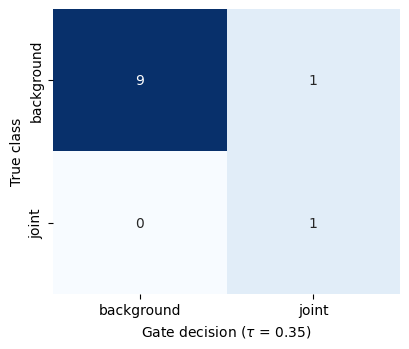

[saved] figures/fig_2_roc_curve.png/.pdf


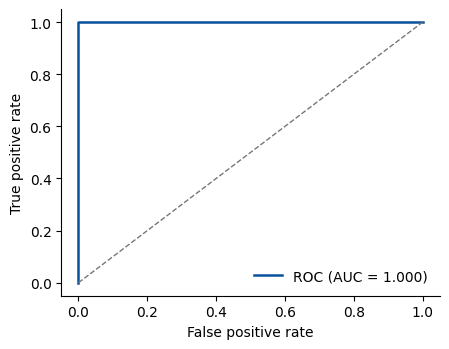

[saved] figures/fig_3_pr_curve.png/.pdf


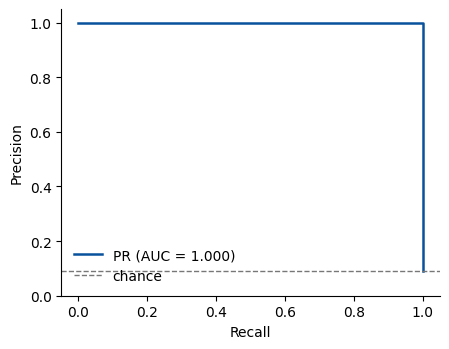

In [ ]:
pte = gate_probs(Xte)
test_tau, test_half = binary_metrics(yte, pte, TAU), binary_metrics(yte, pte, 0.5)
pred_df = pd.DataFrame({"file": [os.path.basename(f) for f in fte], "label": yte, "prob": np.round(pte, 4),
                        "passed_gate_at_tau": (pte >= TAU).astype(int)})
save_table(pred_df, "test_predictions")

ci_rows = []
for name, k, n in [("Recall (sensitivity)", test_tau["TP"], test_tau["TP"] + test_tau["FN"]),
                   ("Precision", test_tau["TP"], test_tau["TP"] + test_tau["FP"]),
                   ("Specificity", test_tau["TN"], test_tau["TN"] + test_tau["FP"]),
                   ("Accuracy", test_tau["TP"] + test_tau["TN"], test_tau["n"])]:
    lo, hi = clopper_pearson(k, n)
    ci_rows.append({"metric": name, "count": f"{k}/{n}", "estimate_%": pct(k / n if n else np.nan),
                    "ci_low_%": pct(lo), "ci_high_%": pct(hi)})
ci_df = pd.DataFrame(ci_rows)
save_table(ci_df, "test_metrics_ci")
for k in ["TP", "FP", "FN", "TN", "passed", "recall", "precision", "specificity", "accuracy"]:
    record(f"test_tau_{k}", test_tau[k])
record("test_ci", ci_rows)

# Confusion matrix at the operating threshold
cm = confusion_matrix(yte, (pte >= TAU).astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.2, 3.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["background", "joint"], yticklabels=["background", "joint"])
ax.set_xlabel(rf"Gate decision ($\tau$ = {TAU})"); ax.set_ylabel("True class")
fig.tight_layout(); save_fig(fig, "fig_1_confusion_matrix"); plt.show()

if 0 < yte.sum() < len(yte):
    fpr, tpr, _ = roc_curve(yte, pte); p_c, r_c, _ = precision_recall_curve(yte, pte)
    roc_auc, pr_auc = auc(fpr, tpr), auc(r_c, p_c)
    record("test_roc_auc", round(float(roc_auc), 4)); record("test_pr_auc", round(float(pr_auc), 4))
    fig, ax = plt.subplots(figsize=(4.6, 3.6))
    ax.plot(fpr, tpr, color="#08519c", lw=1.8, label=f"ROC (AUC = {roc_auc:.3f})")
    ax.plot([0, 1], [0, 1], color="#777777", ls="--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, loc="lower right")
    fig.tight_layout(); save_fig(fig, "fig_2_roc_curve"); plt.show()
    fig, ax = plt.subplots(figsize=(4.6, 3.6))
    ax.plot(r_c, p_c, color="#08519c", lw=1.8, label=f"PR (AUC = {pr_auc:.3f})")
    ax.axhline(yte.mean(), color="#777777", ls="--", lw=1, label="chance")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1.05)
    ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, loc="lower left")
    fig.tight_layout(); save_fig(fig, "fig_3_pr_curve"); plt.show()

## 7. Seed variability (optional, recommended for the paper)
Retrains the complete gate for each seed in `SEED_VARIABILITY` and reports validation and test metrics at tau. Reviewers will ask for this because the held-out sequence is small and earlier runs differed.

In [ ]:
seed_rows = []
for s in [CONFIG["SEED"]] + list(SEED_VARIABILITY):
    if s == CONFIG["SEED"]:
        m, info = classifier, train_info
    else:
        print(f"\n===== Training gate with seed {s} =====")
        m, _, info = train_gate(s, f"seed{s}")
    f_ = tf.function(lambda x, m=m: m(x, training=False))
    pv = np.concatenate([f_(tf.constant(Xva[i:i + 16])).numpy().ravel() for i in range(0, len(Xva), 16)])
    pt = np.concatenate([f_(tf.constant(Xte[i:i + 16])).numpy().ravel() for i in range(0, len(Xte), 16)])
    v, t = binary_metrics(yva, pv, TAU), binary_metrics(yte, pt, TAU)
    seed_rows.append({"seed": s, "best_epoch": info.get("best_epoch"),
                      "val_recall": v["recall"], "val_precision": v["precision"], "val_FP": v["FP"],
                      "test_recall": t["recall"], "test_precision": t["precision"], "test_FP": t["FP"]})
seed_df = pd.DataFrame(seed_rows)
save_table(seed_df, "seed_variability")
if len(seed_df) > 1:
    agg = seed_df.drop(columns=["seed", "best_epoch"]).agg(["mean", "std"]).T
    display(agg); agg.to_csv(os.path.join(DIRS["tables"], "seed_variability_summary.csv"))
    record("seed_variability", seed_df.to_dict(orient="records"))

,seed,best_epoch,val_recall,val_precision,val_FP,test_recall,test_precision,test_FP
0,1337,36,1.0,0.114286,62,1.0,0.5,1


[saved] /content/drive/MyDrive/M2Project/results_mlwa/tables/seed_variability.csv


## 8. Stage 2: HED engine (OpenCV DNN) and Grad-CAM
The gate runs in TensorFlow and HED in OpenCV DNN, inside one Python process. HED needs a custom `Crop` layer.

In [ ]:
class CropLayer(object):
    def __init__(self, params, blobs):
        self.xstart = self.xend = self.ystart = self.yend = 0
    def getMemoryShapes(self, inputs):
        in_shape, target = inputs[0], inputs[1]
        self.ystart = int((in_shape[2] - target[2]) / 2)
        self.xstart = int((in_shape[3] - target[3]) / 2)
        self.yend, self.xend = self.ystart + target[2], self.xstart + target[3]
        return [[in_shape[0], in_shape[1], target[2], target[3]]]
    def forward(self, inputs):
        return [inputs[0][:, :, self.ystart:self.yend, self.xstart:self.xend]]

for p in (CONFIG["HED_PROTOTXT"], CONFIG["HED_MODEL"]):
    if not os.path.exists(p):
        raise FileNotFoundError(f"HED file not found: {p}\nDownload deploy.prototxt and hed_pretrained_bsds.caffemodel "
                                "(https://github.com/s9xie/hed) and update CONFIG['HED_PROTOTXT'/'HED_MODEL'].")
try:
    cv2.dnn_unregisterLayer("Crop")
except Exception:
    pass
cv2.dnn_registerLayer("Crop", CropLayer)
hed_engine = cv2.dnn.readNetFromCaffe(CONFIG["HED_PROTOTXT"], CONFIG["HED_MODEL"])
hed_engine.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
hed_engine.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)

def hed_forward(img_bgr_uint8):
    h, w = img_bgr_uint8.shape[:2]
    blob = cv2.dnn.blobFromImage(img_bgr_uint8, 1.0, (w, h), CONFIG["HED_MEAN"], swapRB=False, crop=False)
    hed_engine.setInput(blob)
    return hed_engine.forward()[0, 0]

def rgb_float_to_bgr_uint8(img):
    return cv2.cvtColor(np.clip(img, 0, 255).astype(np.uint8), cv2.COLOR_RGB2BGR)

_ = hed_forward(rgb_float_to_bgr_uint8(Xte[0]))
print("HED engine ready (OpenCV", cv2.__version__, ")")

def gradcam(img_rgb_float):
    # Grad-CAM on the last ResNet50 block for the gate output (Eq. 5 of the paper)
    aug = classifier.get_layer("structural_augmentation")
    dense = classifier.get_layer("decision_node")
    backbone = next(l for l in classifier.layers if "resnet" in l.name.lower())
    gap = next(l for l in classifier.layers if isinstance(l, layers.GlobalAveragePooling2D))
    x = tf.constant(img_rgb_float[None], tf.float32)
    with tf.GradientTape() as tape:
        z = tf.keras.applications.resnet50.preprocess_input(aug(x, training=False))
        fmap = backbone(z, training=False)
        tape.watch(fmap)
        y_hat = dense(gap(fmap))[:, 0]
    grads = tape.gradient(y_hat, fmap)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(fmap[0] * weights, axis=-1)).numpy()
    return cam / (cam.max() + 1e-8)

HED engine ready (OpenCV 4.12.0 )


[saved] figures/fig_positive_case.png/.pdf


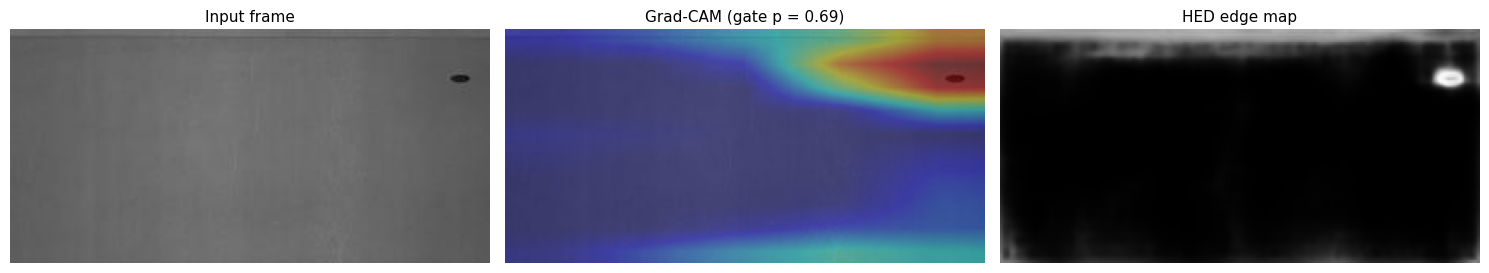

[saved] figures/fig_dropped_a.png/.pdf
[saved] figures/fig_dropped_b.png/.pdf
[saved] figures/fig_dropped_c.png/.pdf
[saved] figures/fig_test_gallery.png/.pdf


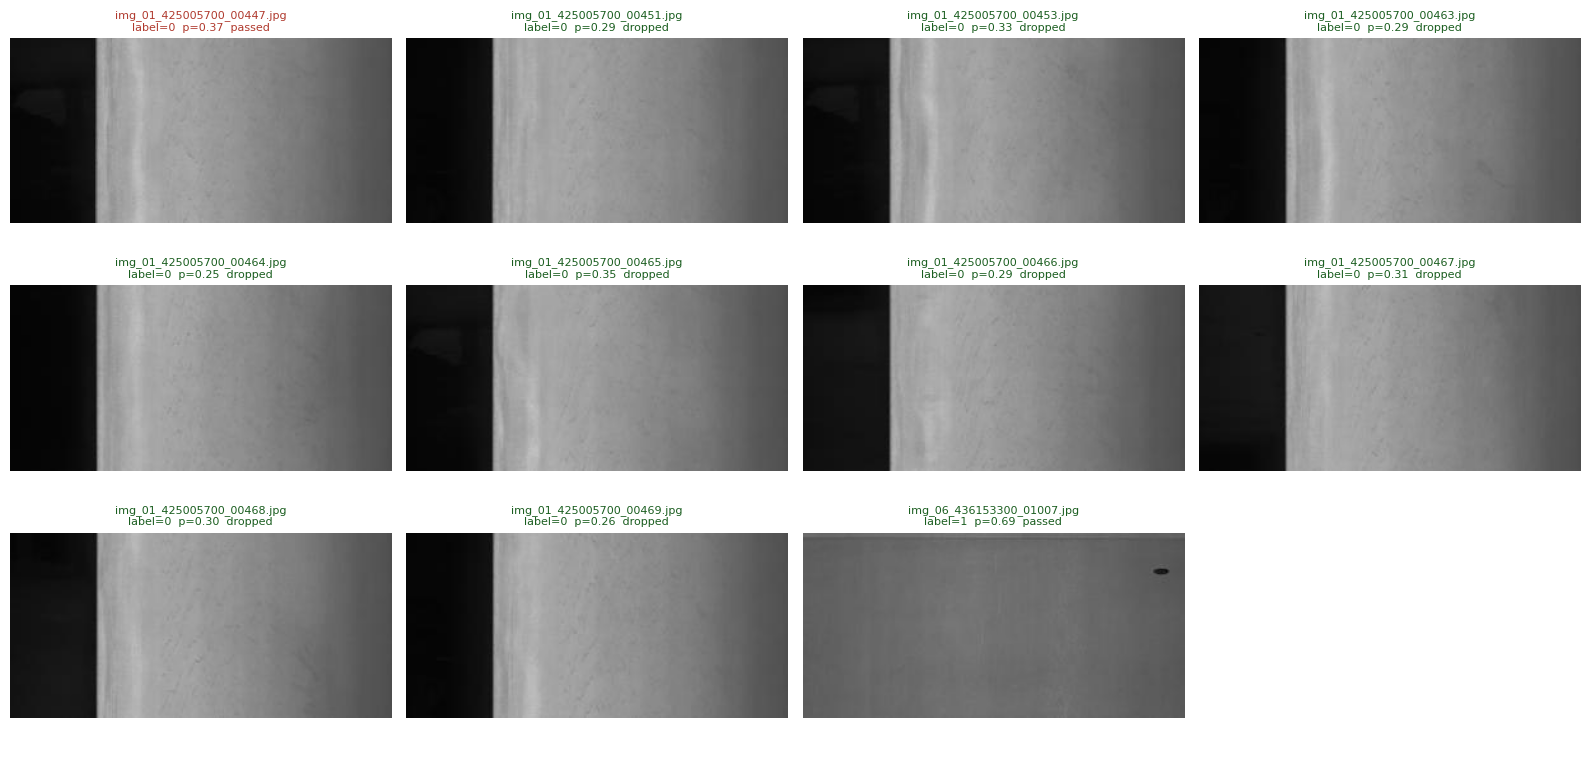

[saved] figures/fig_canny_vs_hed.png/.pdf


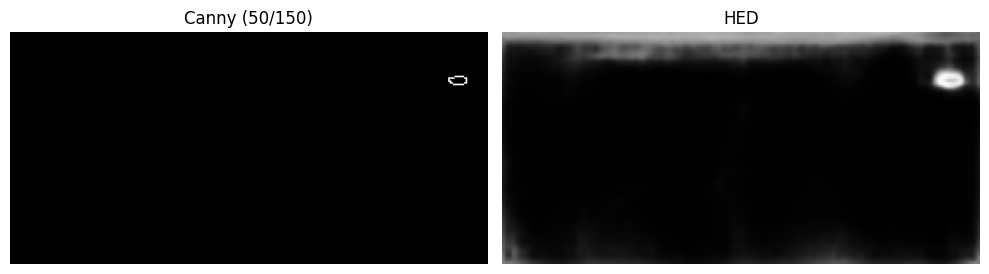

In [ ]:
# --- 8.1 Qualitative figures (fixed frames, no one-off latencies in the titles) -------------
def overlay(img_rgb, cam):
    cam_r = cv2.resize(cam, (img_rgb.shape[1], img_rgb.shape[0]))
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam_r), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(img_rgb, 0.6, heat, 0.4, 0)

def raw_rgb(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

order = np.argsort([os.path.basename(f) for f in fte])
pos_idx = [i for i in order if yte[i] == 1]
neg_idx = [i for i in order if yte[i] == 0]

# positive frame(s): input | Grad-CAM | HED edge map (HED at the frame's original resolution)
for k, i in enumerate(pos_idx):
    raw = raw_rgb(fte[i])
    cam = gradcam(Xte[i])
    edges = hed_forward(cv2.cvtColor(raw, cv2.COLOR_RGB2BGR))
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    for ax, im, title in zip(axes, [raw, overlay(raw, cam), edges],
                             ["Input frame", f"Grad-CAM (gate p = {pte[i]:.2f})", "HED edge map"]):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None); ax.set_title(title, fontsize=11); ax.axis("off")
    fig.tight_layout(); save_fig(fig, "fig_positive_case" if k == 0 else f"fig_positive_case_{k+1}"); plt.show()

# dropped frames: three background frames (first three by file name) for the paper, plus a full gallery
for letter, i in zip("abc", neg_idx[:3]):
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.imshow(raw_rgb(fte[i])); ax.axis("off")
    ax.set_title(f"Dropped at gate (p = {pte[i]:.2f} < {TAU})", fontsize=11, color="#b03a2e")
    fig.tight_layout(); save_fig(fig, f"fig_dropped_{letter}"); plt.close(fig)

n = len(order); cols = 4; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 2.6 * rows))
for ax in np.ravel(axes): ax.axis("off")
for ax, i in zip(np.ravel(axes), order):
    ax.imshow(raw_rgb(fte[i]))
    ok = int(pte[i] >= TAU) == yte[i]
    ax.set_title(f"{os.path.basename(fte[i])}\nlabel={yte[i]}  p={pte[i]:.2f}  {'passed' if pte[i] >= TAU else 'dropped'}",
                 fontsize=8, color="#1b5e20" if ok else "#b03a2e")
fig.tight_layout(); save_fig(fig, "fig_test_gallery"); plt.show()

# Canny vs HED on the positive frame (supports the qualitative claim about classical filters)
if pos_idx:
    i = pos_idx[0]; raw = raw_rgb(fte[i])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    axes[0].imshow(cv2.Canny(cv2.cvtColor(raw, cv2.COLOR_RGB2GRAY), 50, 150), cmap="gray"); axes[0].set_title("Canny (50/150)")
    axes[1].imshow(hed_forward(cv2.cvtColor(raw, cv2.COLOR_RGB2BGR)), cmap="gray"); axes[1].set_title("HED")
    for ax in axes: ax.axis("off")
    fig.tight_layout(); save_fig(fig, "fig_canny_vs_hed"); plt.show()

## 9. Latency benchmark (CPU, end to end)
For every frame of the validation and test sets: Canny, gate only, un-gated HED, and the **gated pipeline timed as a whole** (gate + HED only if p >= tau). All inputs are 300x146. TensorFlow is pinned to the CPU even on a GPU runtime. The *HED stage only* figure (the quantity reported as 0.0415 s in the first draft) is computed on the 11 test frames.

In [ ]:
X_bench = np.concatenate([Xva, Xte]); is_test = np.r_[np.zeros(len(Xva), bool), np.ones(len(Xte), bool)]
BGR = [rgb_float_to_bgr_uint8(im) for im in X_bench]
GRAY = [cv2.cvtColor(b, cv2.COLOR_BGR2GRAY) for b in BGR]

if ENV["gpus"]:
    print("WARNING: GPU runtime detected. The paper reports CPU-only timings; the gate is re-loaded on the CPU, "
          "but a CPU-only runtime is recommended for the final benchmark.")
with tf.device("/CPU:0"):
    bench_model = tf.keras.models.load_model(CONFIG["GATE_MODEL_SAVE_PATH"]) if ENV["gpus"] else classifier
    @tf.function(reduce_retracing=True)
    def _gate_cpu(x):
        return bench_model(x, training=False)
    def gate_one(img):
        return float(_gate_cpu(tf.constant(img[None]))[0, 0])

    for _ in range(CONFIG["BENCH_WARMUP"]):
        gate_one(X_bench[0]); hed_forward(BGR[0]); cv2.Canny(GRAY[0], 50, 150)

    rows = []
    for rep in range(CONFIG["BENCH_REPEATS"]):
        for j, (img, bgr, gray) in enumerate(zip(X_bench, BGR, GRAY)):
            t = time.perf_counter(); cv2.Canny(gray, 50, 150); t_canny = time.perf_counter() - t
            t = time.perf_counter(); gate_one(img); t_gate = time.perf_counter() - t
            t = time.perf_counter(); hed_forward(bgr); t_hed = time.perf_counter() - t
            t0 = time.perf_counter(); p = gate_one(img); t1 = time.perf_counter()
            routed = p >= TAU
            if routed:
                hed_forward(bgr)
            t2 = time.perf_counter()
            rows.append({"repeat": rep, "frame": j, "test_frame": bool(is_test[j]), "canny": t_canny, "gate": t_gate,
                         "hed": t_hed, "pipeline": t2 - t0, "hed_stage": (t2 - t1) if routed else 0.0, "routed": routed})
bench = pd.DataFrame(rows)
bench.to_csv(os.path.join(DIRS["tables"], "benchmark_per_frame.csv"), index=False)

L = {"canny": bench.canny.mean(), "gate": bench.gate.mean(), "hed": bench.hed.mean(),
     "pipeline": bench.pipeline.mean(), "hed_stage_test": bench[bench.test_frame].hed_stage.mean()}
q_bench = bench.routed.mean()
summary = pd.DataFrame([
    {"component": "Canny", "mean_s": L["canny"], "median_s": bench.canny.median(), "sd_s": bench.canny.std()},
    {"component": "Gate only (ResNet50)", "mean_s": L["gate"], "median_s": bench.gate.median(), "sd_s": bench.gate.std()},
    {"component": "Un-gated HED", "mean_s": L["hed"], "median_s": bench.hed.median(), "sd_s": bench.hed.std()},
    {"component": "Gated, HED stage only (test frames)", "mean_s": L["hed_stage_test"],
     "median_s": bench[bench.test_frame].hed_stage.median(), "sd_s": bench[bench.test_frame].hed_stage.std()},
    {"component": "Gated, end-to-end", "mean_s": L["pipeline"], "median_s": bench.pipeline.median(), "sd_s": bench.pipeline.std()},
])
summary["fps"] = 1 / summary.mean_s
summary["speedup_vs_hed"] = L["hed"] / summary.mean_s
save_table(summary.round(4), "benchmark_summary")
rho = L["gate"] / L["hed"]
print(f"Frames routed to HED: {100*q_bench:.1f}% | rho = L_gate/L_HED = {rho:.3f} | "
      f"end-to-end: {L['pipeline']:.4f} s ({1/L['pipeline']:.1f} FPS, {L['hed']/L['pipeline']:.2f}x)")
for k, v in L.items():
    record(f"lat_{k}", round(float(v), 4))
record("bench_routed_fraction", round(float(q_bench), 4)); record("rho", round(float(rho), 4))
record("bench_frames", int(len(X_bench))); record("bench_repeats", CONFIG["BENCH_REPEATS"])

,component,mean_s,median_s,sd_s,fps,speedup_vs_hed
0,Canny,0.0003,0.0002,0.0001,3773.9202,1882.3195
1,Gate only (ResNet50),0.1759,0.1473,0.0503,5.6838,2.8349
2,Un-gated HED,0.4988,0.4558,0.0849,2.0049,1.0000
3,"Gated, HED stage only (test frames)",0.0895,0.0000,0.1946,11.1753,5.5739
4,"Gated, end-to-end",0.5459,0.5955,0.2355,1.8320,0.9137


[saved] /content/drive/MyDrive/M2Project/results_mlwa/tables/benchmark_summary.csv
Frames routed to HED: 75.0% | rho = L_gate/L_HED = 0.353 | end-to-end: 0.5459 s (1.8 FPS, 0.91x)


[saved] figures/fig_4_latency_breakdown.png/.pdf


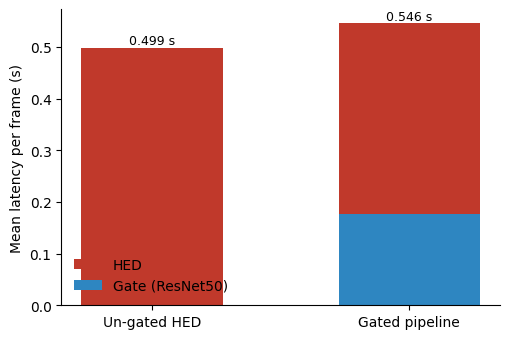

[saved] figures/fig_throughput_sensitivity.png/.pdf


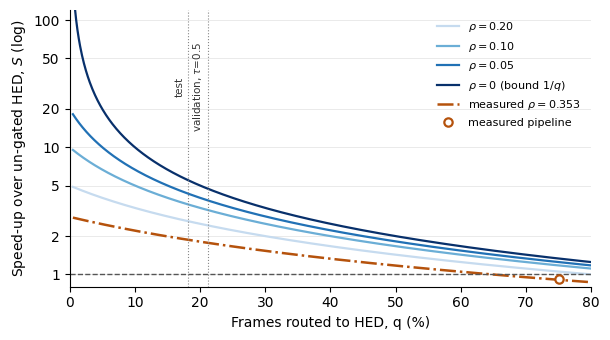

In [ ]:
# --- 9.1 Latency figure and analytic speed-up figure (Eq. 9: S = 1 / (rho + q)) -----------
fig, ax = plt.subplots(figsize=(5.2, 3.5))
ax.bar(["Un-gated HED", "Gated pipeline"], [L["hed"], 0], color="#c0392b", width=0.55, label="HED")
ax.bar(["Gated pipeline"], [L["gate"]], color="#2e86c1", width=0.55, label="Gate (ResNet50)")
ax.bar(["Gated pipeline"], [L["pipeline"] - L["gate"]], bottom=[L["gate"]], color="#c0392b", width=0.55)
for x, v in [(0, L["hed"]), (1, L["pipeline"])]:
    ax.text(x, v, f"{v:.3f} s", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Mean latency per frame (s)"); ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False)
fig.tight_layout(); save_fig(fig, "fig_4_latency_breakdown"); plt.show()

from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
q_test, q_val_half = test_tau["passed"] / test_tau["n"], val_half["passed"] / val_half["n"]
qq = np.linspace(0.005, 1.0, 1000)
fig, ax = plt.subplots(figsize=(6.2, 3.5))
for r_, c in zip([0.20, 0.10, 0.05, 0.0], ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]):
    ax.plot(qq * 100, 1 / (r_ + qq), color=c, lw=1.6,
            label=r"$\rho = 0$ (bound $1/q$)" if r_ == 0 else rf"$\rho = {r_:.2f}$")
ax.plot(qq * 100, 1 / (rho + qq), color="#b5520c", lw=1.8, ls="-.", label=rf"measured $\rho = {rho:.3f}$")
ax.plot([100 * q_bench], [L["hed"] / L["pipeline"]], "o", mfc="white", mec="#b5520c", mew=1.6, zorder=5,
        label="measured pipeline")
ax.axhline(1, color="#555555", lw=1, ls="--")
for qv, txt in [(q_test, "test"), (q_val_half, r"validation, $\tau$=0.5")]:
    ax.axvline(100 * qv, color="#888888", lw=0.8, ls=":")
    ax.text(100 * qv - 0.6, 30, txt, rotation=90, ha="right", va="center", fontsize=7.5, color="#333333")
x_max = min(100, max(60, 100 * max(q_test, q_val_half, q_bench) + 5))
ax.set_yscale("log"); ax.set_ylim(min(0.8, 0.9 * L["hed"] / L["pipeline"]), 120); ax.set_xlim(0, x_max)
ax.yaxis.set_major_locator(FixedLocator([1, 2, 5, 10, 20, 50, 100]))
ax.yaxis.set_major_formatter(FixedFormatter(["1", "2", "5", "10", "20", "50", "100"])); ax.yaxis.set_minor_locator(NullLocator())
ax.set_xlabel("Frames routed to HED, q (%)"); ax.set_ylabel(r"Speed-up over un-gated HED, $S$ (log)")
ax.grid(axis="y", color="#e6e6e6", lw=0.6); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout(); save_fig(fig, "fig_throughput_sensitivity"); plt.show()

## 10. Ablation study and mirrored-frame stress test
Protocol of the original experiments, kept so that the paper's ablation stays comparable: each variant is trained from ImageNet weights with a **frozen** backbone for `ABLATION_EPOCHS` epochs (no fine-tuning phase), dropout 0.25, horizontal flips only, and evaluated on the held-out test frames (tau = 0.35 for focal variants, 0.5 for BCE). Results are cached in `tables/ablation.csv`.

In [ ]:
VARIANTS = [
    {"name": "Naive Baseline (BCE)", "focal": False, "weights": False, "reg": True, "aug": True},
    {"name": "Unregularized Focal Gate", "focal": True, "weights": True, "reg": False, "aug": True},
    {"name": "Environment-Static Gate", "focal": True, "weights": True, "reg": True, "aug": False},
    {"name": "Proposed Focal Gate", "focal": True, "weights": True, "reg": True, "aug": True},
]

def build_ablation_model(v, seed):
    set_all_seeds(seed)
    shape = CONFIG["IMG_SIZE"] + (CONFIG["CHANNELS"],)
    base = tf.keras.applications.ResNet50(input_shape=shape, include_top=False, weights=CONFIG["BACKBONE_WEIGHTS"])
    base.trainable = False
    inputs = layers.Input(shape=shape); x = inputs
    if v["aug"]:
        x = tf.keras.Sequential([layers.RandomFlip("horizontal", seed=seed),
                                 layers.RandomTranslation(0.1, 0.1, seed=seed + 1),
                                 layers.RandomBrightness(0.2, seed=seed + 2)])(x)
    x = tf.keras.applications.resnet50.preprocess_input(x)
    x = layers.GlobalAveragePooling2D()(base(x, training=False))
    reg = None
    if v["reg"]:
        x = layers.Dropout(CONFIG["ABLATION_DROPOUT"], seed=seed + 3)(x); reg = tf.keras.regularizers.l2(CONFIG["L2"])
    out = layers.Dense(1, activation="sigmoid", kernel_regularizer=reg)(x)
    m = models.Model(inputs, out)
    loss = (tf.keras.losses.BinaryFocalCrossentropy(gamma=CONFIG["FOCAL_GAMMA"], alpha=CONFIG["FOCAL_ALPHA"])
            if v["focal"] else tf.keras.losses.BinaryCrossentropy())
    m.compile(optimizer=optimizers.Adam(CONFIG["ABLATION_LR"]), loss=loss)
    return m

ABL_PATH = os.path.join(DIRS["tables"], "ablation.csv")
STRESS_PATH = os.path.join(DIRS["tables"], "stress_test.csv")
X_flip = Xte[:, :, ::-1, :].copy()     # horizontal mirror

if RUN_ABLATION and (FORCE_ABLATION or not os.path.exists(ABL_PATH)):
    abl_rows, stress_rows = [], []
    for v in VARIANTS:
        t0 = time.time(); print(f"Training variant: {v['name']} ...")
        m = build_ablation_model(v, CONFIG["SEED"])
        tr_ds, _ = train_val_datasets(CONFIG["SEED"])
        m.fit(tr_ds, epochs=CONFIG["ABLATION_EPOCHS"], class_weight=class_weights if v["weights"] else None, verbose=0)
        thr = TAU if v["focal"] else 0.5
        f_ = tf.function(lambda x, m=m: m(x, training=False))
        p = np.concatenate([f_(tf.constant(Xte[i:i + 16])).numpy().ravel() for i in range(0, len(Xte), 16)])
        met = binary_metrics(yte, p, thr)
        abl_rows.append({"variant": v["name"], "focal_loss": v["focal"], "class_weights": v["weights"],
                         "regularization": v["reg"], "augmentation": v["aug"], "threshold": thr,
                         **{k: met[k] for k in ["TP", "FP", "FN", "TN", "recall", "precision"]},
                         "minutes": round((time.time() - t0) / 60, 1)})
        if v["name"] in ("Environment-Static Gate", "Proposed Focal Gate"):
            pf = np.concatenate([f_(tf.constant(X_flip[i:i + 16])).numpy().ravel() for i in range(0, len(X_flip), 16)])
            mf = binary_metrics(yte, pf, TAU)
            stress_rows.append({"variant": v["name"], **{k: mf[k] for k in ["TP", "FP", "FN", "TN", "recall", "precision"]}})
        tf.keras.backend.clear_session()
    pd.DataFrame(abl_rows).to_csv(ABL_PATH, index=False); pd.DataFrame(stress_rows).to_csv(STRESS_PATH, index=False)

if os.path.exists(ABL_PATH):
    abl_df, stress_df = pd.read_csv(ABL_PATH), pd.read_csv(STRESS_PATH)
    show = abl_df.copy(); show["recall_%"] = show.recall.map(pct); show["precision_%"] = show.precision.map(pct)
    print("Ablation (held-out test frames); precision 'n/a' = no positive predictions:")
    display(show.drop(columns=["recall", "precision"]))
    print("Mirrored-frame stress test:"); display(stress_df)
    record("ablation", abl_df.to_dict(orient="records")); record("stress_test", stress_df.to_dict(orient="records"))
else:
    abl_df = stress_df = None
    print("Ablation skipped (RUN_ABLATION = False and no cached results).")

Training variant: Naive Baseline (BCE) ...
Found 213 files belonging to 2 classes.
Found 85 files belonging to 2 classes.
Training variant: Unregularized Focal Gate ...
Found 213 files belonging to 2 classes.
Found 85 files belonging to 2 classes.
Training variant: Environment-Static Gate ...
Found 213 files belonging to 2 classes.
Found 85 files belonging to 2 classes.
Training variant: Proposed Focal Gate ...
Found 213 files belonging to 2 classes.
Found 85 files belonging to 2 classes.
Ablation (held-out test frames); precision 'n/a' = no positive predictions:


,variant,focal_loss,class_weights,regularization,augmentation,threshold,TP,FP,FN,TN,minutes,recall_%,precision_%
0,Naive Baseline (BCE),False,False,True,True,0.50,0,0,1,10,32.4,0.0,n/a
1,Unregularized Focal Gate,True,True,False,True,0.35,1,0,0,10,30.5,100.0,100.0
2,Environment-Static Gate,True,True,True,False,0.35,1,0,0,10,29.4,100.0,100.0
3,Proposed Focal Gate,True,True,True,True,0.35,1,0,0,10,30.6,100.0,100.0


Mirrored-frame stress test:


,variant,TP,FP,FN,TN,recall,precision
0,Environment-Static Gate,1,3,0,7,1.0,0.25
1,Proposed Focal Gate,1,1,0,9,1.0,0.50


## 11. Export for the paper
Writes `overleaf/results_macros.tex` (every number used in the manuscript), copies the figures under the file names used in the Overleaf project, zips both as `overleaf_update.zip`, and saves `results_summary.json`.

In [ ]:
def ci_str(k, n):
    lo, hi = clopper_pearson(k, n)
    return f"[{pct(lo)}\\%, {pct(hi, 0) if hi == 1 else pct(hi)}\\%]"

def fnum(x, nd=4):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{nd}f}"

M = {}
# benchmark
M.update({"LCanny": fnum(L["canny"]), "LHed": fnum(L["hed"]), "FPSHed": f"{1/L['hed']:.1f}",
          "LHedStage": fnum(L["hed_stage_test"]), "HedRed": str(int(round(100*(1-L["hed_stage_test"]/L["hed"])))),
          "HedStageSpeedUp": f"{L['hed']/L['hed_stage_test']:.1f}" if L["hed_stage_test"] > 0 else "n/a",
          "LGate": fnum(L["gate"]), "LPipe": fnum(L["pipeline"]), "FPSPipe": f"{1/L['pipeline']:.1f}",
          "SpeedUp": f"{L['hed']/L['pipeline']:.1f}", "PipeRed": str(int(round(100*(1-L["pipeline"]/L["hed"])))),
          "RhoGate": f"{rho:.3f}", "NBench": str(len(X_bench)), "NRep": str(CONFIG["BENCH_REPEATS"]),
          "PassRate": f"{100*q_bench:.1f}"})
# training
M.update({"BestEpoch": str(train_info.get("best_epoch", "n/a")), "StopEpoch": str(train_info.get("stopped_epoch", "n/a")),
          "ParamsTotal": f"{train_info.get('total', classifier.count_params()):,}".replace(",", "{,}"),
          "ParamsTrainable": f"{train_info.get('trainable_phase2', 0):,}".replace(",", "{,}")})
# validation
M.update({"ValPRAUC": f"{val_prauc:.2f}", "ValNPos": str(int(yva.sum())), "ValNNeg": str(int((yva == 0).sum())),
          "ValTPTau": str(val_tau["TP"]), "ValFPTau": str(val_tau["FP"]), "ValPassTau": str(val_tau["passed"]),
          "ValRecTau": pct(val_tau["recall"]), "ValPrecTau": pct(val_tau["precision"]),
          "ValTPHalf": str(val_half["TP"]), "ValFPHalf": str(val_half["FP"]), "ValPassHalf": str(val_half["passed"]),
          "ValRecHalf": pct(val_half["recall"]), "ValPrecHalf": pct(val_half["precision"]),
          "ValQHalf": f"{q_val_half:.3f}", "ValSBoundHalf": f"{1/q_val_half:.1f}" if q_val_half > 0 else "n/a"})
# test
tp, fp, fn, tn = test_tau["TP"], test_tau["FP"], test_tau["FN"], test_tau["TN"]
M.update({"TestN": str(test_tau["n"]), "TestTP": str(tp), "TestFP": str(fp), "TestFN": str(fn), "TestTN": str(tn),
          "TestPass": str(test_tau["passed"]), "TestQ": f"{q_test:.3f}",
          "TestSBound": f"{1/q_test:.1f}" if q_test > 0 else "n/a",
          "TestRec": pct(test_tau["recall"], 0), "TestPrec": pct(test_tau["precision"], 0),
          "TestSpec": pct(test_tau["specificity"], 0), "TestAcc": pct(test_tau["accuracy"], 0),
          "TestRecCI": ci_str(tp, tp + fn), "TestPrecCI": ci_str(tp, tp + fp),
          "TestSpecCI": ci_str(tn, tn + fp), "TestAccCI": ci_str(tp + tn, test_tau["n"]),
          "TestROCAUC": f"{RESULTS['test_roc_auc']['value']:.3f}" if "test_roc_auc" in RESULTS else "n/a",
          "TestPRAUC": f"{RESULTS['test_pr_auc']['value']:.3f}" if "test_pr_auc" in RESULTS else "n/a",
          "TestRecCount": f"{tp}/{tp+fn}", "TestPrecCount": f"{tp}/{tp+fp}",
          "TestSpecCount": f"{tn}/{tn+fp}", "TestAccCount": f"{tp+tn}/{test_tau['n']}"})
# ablation and stress test (yellow placeholders if the ablation was not run)
for v_ in ["Naive", "Unreg", "Static", "Prop"]:
    M[f"Abl{v_}Rec"] = M[f"Abl{v_}Prec"] = r"\tbd{n/r}"
for v_ in ["Static", "Prop"]:
    M[f"Stress{v_}Rec"] = M[f"Stress{v_}Prec"] = r"\tbd{n/r}"
if abl_df is not None:
    keys = {"Naive Baseline (BCE)": "Naive", "Unregularized Focal Gate": "Unreg",
            "Environment-Static Gate": "Static", "Proposed Focal Gate": "Prop"}
    for _, r in abl_df.iterrows():
        M[f"Abl{keys[r.variant]}Rec"] = pct(r.recall); M[f"Abl{keys[r.variant]}Prec"] = pct(r.precision)
    for _, r in stress_df.iterrows():
        M[f"Stress{keys[r.variant]}Rec"] = pct(r.recall); M[f"Stress{keys[r.variant]}Prec"] = pct(r.precision)

stamp = f"%% Generated {ENV['timestamp_utc']} UTC | TF {ENV['tensorflow']} | OpenCV {ENV['opencv']} | CPU: {ENV['cpu_model']}"
lines = [stamp, r"\providecommand{\tbd}[1]{\colorbox{yellow}{#1}}"]
lines += [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in M.items()]
macro_text = "\n".join(lines) + "\n"
with open(os.path.join(DIRS["overleaf"], "results_macros.tex"), "w") as f:
    f.write(macro_text)

# figures under the Overleaf file names
ov_fig = os.path.join(DIRS["overleaf"], "figures"); os.makedirs(ov_fig, exist_ok=True)
for name in ["fig_1_confusion_matrix", "fig_2_roc_curve", "fig_3_pr_curve", "fig_4_latency_breakdown",
             "fig_throughput_sensitivity", "fig_positive_case", "fig_dropped_a", "fig_dropped_b", "fig_dropped_c",
             "fig_training_curves", "fig_validation_pr_curve", "fig_test_gallery", "fig_canny_vs_hed"]:
    src = os.path.join(DIRS["figures"], f"{name}.png")
    if os.path.exists(src):
        shutil.copy(src, os.path.join(ov_fig, f"{name}.png"))
shutil.make_archive(os.path.join(RESULTS_DIR, "overleaf_update"), "zip", DIRS["overleaf"])

record("latex_macros", M)
with open(os.path.join(RESULTS_DIR, "results_summary.json"), "w") as f:
    json.dump({"environment": ENV, "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()},
               "results": RESULTS}, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

print(macro_text)
print("Saved:", os.path.join(RESULTS_DIR, "overleaf_update.zip"))

%% Generated 2026-10-17 00:32:48 UTC | TF 2.21.0 | OpenCV 4.12.0 | CPU: Intel(R) Xeon(R) CPU @ 2.20GHz
\providecommand{\tbd}[1]{\colorbox{yellow}{#1}}
\newcommand{\LCanny}{0.0003}
\newcommand{\LHed}{0.4988}
\newcommand{\FPSHed}{2.0}
\newcommand{\LHedStage}{0.0895}
\newcommand{\HedRed}{82}
\newcommand{\HedStageSpeedUp}{5.6}
\newcommand{\LGate}{0.1759}
\newcommand{\LPipe}{0.5459}
\newcommand{\FPSPipe}{1.8}
\newcommand{\SpeedUp}{0.9}
\newcommand{\PipeRed}{-9}
\newcommand{\RhoGate}{0.353}
\newcommand{\NBench}{96}
\newcommand{\NRep}{5}
\newcommand{\PassRate}{75.0}
\newcommand{\BestEpoch}{36}
\newcommand{\StopEpoch}{44}
\newcommand{\ParamsTotal}{23{,}589{,}761}
\newcommand{\ParamsTrainable}{4{,}467{,}713}
\newcommand{\ValPRAUC}{1.00}
\newcommand{\ValNPos}{8}
\newcommand{\ValNNeg}{77}
\newcommand{\ValTPTau}{8}
\newcommand{\ValFPTau}{62}
\newcommand{\ValPassTau}{70}
\newcommand{\ValRecTau}{100.0}
\newcommand{\ValPrecTau}{11.4}
\newcommand{\ValTPHalf}{8}
\newcommand{\ValFPHalf}{10}
\newcommand{

In [ ]:
# --- 11.1 One-page overview of the numbers that appear in the paper -------------------------
overview = pd.DataFrame([
    ("Dataset", "train / val / test frames", f"{len(ytr)} / {len(yva)} / {len(yte)}"),
    ("Dataset", "val joints / background", f"{M['ValNPos']} / {M['ValNNeg']}"),
    ("Dataset", "test frames sharing a recording with train/val", f"{shared}/{len(leak_df)}"),
    ("Training", "best (restored) / stopped epoch", f"{M['BestEpoch']} / {M['StopEpoch']}"),
    ("Training", "parameters total / trainable (phase 2)", f"{M['ParamsTotal']} / {M['ParamsTrainable']}".replace("{,}", ",")),
    ("Validation", "PR-AUC", M["ValPRAUC"]),
    ("Validation", f"tau={TAU}: TP/FP, recall, precision", f"{M['ValTPTau']}/{M['ValFPTau']}, {M['ValRecTau']}%, {M['ValPrecTau']}%"),
    ("Validation", "tau=0.5: TP/FP, recall, precision", f"{M['ValTPHalf']}/{M['ValFPHalf']}, {M['ValRecHalf']}%, {M['ValPrecHalf']}%"),
    ("Test", "TP/FP/FN/TN", f"{tp}/{fp}/{fn}/{tn}"),
    ("Test", "recall [95% CI]", f"{M['TestRec']}% {M['TestRecCI']}".replace("\\", "")),
    ("Test", "specificity [95% CI]", f"{M['TestSpec']}% {M['TestSpecCI']}".replace("\\", "")),
    ("Latency", "Canny / gate / HED (s)", f"{M['LCanny']} / {M['LGate']} / {M['LHed']}"),
    ("Latency", "gated end-to-end (s), FPS, speed-up", f"{M['LPipe']}, {M['FPSPipe']}, {M['SpeedUp']}x"),
    ("Latency", "HED stage only on test (s), workload reduction", f"{M['LHedStage']}, {M['HedRed']}%"),
    ("Latency", "rho, frames routed to HED", f"{M['RhoGate']}, {M['PassRate']}%"),
] + ([("Ablation", r.variant, f"recall {pct(r.recall)}%, precision {pct(r.precision)}%") for _, r in abl_df.iterrows()]
     if abl_df is not None else []) +
    ([("Stress test", r.variant, f"precision {pct(r.precision)}% (mirrored)") for _, r in stress_df.iterrows()]
     if stress_df is not None else []),
    columns=["section", "quantity", "value"])
save_table(overview, "paper_numbers_overview")

,section,quantity,value
0,Dataset,train / val / test frames,213 / 85 / 11
1,Dataset,val joints / background,8 / 77
2,Dataset,test frames sharing a recording with train/val,10/11
3,Training,best (restored) / stopped epoch,36 / 44
4,Training,parameters total / trainable (phase 2),"23,589,761 / 4,467,713"
5,Validation,PR-AUC,1.00
6,Validation,"tau=0.35: TP/FP, recall, precision","8/62, 100.0%, 11.4%"
7,Validation,"tau=0.5: TP/FP, recall, precision","8/10, 100.0%, 44.4%"
8,Test,TP/FP/FN/TN,1/1/0/9
9,Test,recall [95% CI],"100% [2.5%, 100%]"


[saved] /content/drive/MyDrive/M2Project/results_mlwa/tables/paper_numbers_overview.csv
